# Frozen Context Reference — synthetic scenario QA

## tl;dr

Executed **17 cases / 73,260 synthetic observed minutes** against saved MX058/M1 and MX017/M1 frozen Profiles. All17 behavioral expectations passed; four accepted MX058 steady modes have **17,280 within-Reference minutes and zero flags**. In the six-hour/day CP2 raised plateau, **1,068 minutes require new-level review** and12minutes are deviations. Stable values outside the Reference are not adopted as Normal. One-minute spikes are detected but the aggregate flag rate remains below1%.

Valve command alone does not create an anomaly. Delayed response remains unsupported because this MX058/M1 Profile has **no accepted Transition templates**. Real OFF-only MX017 abstains on excluded ON and evaluates the first returning OFF minute immediately.

These are software scenarios, not healthy/fault accuracy, real sensor data, elapsed future days or approval evidence. Source/Profile/review/Active/Event/job state was not written. No Mock button was added.


## Context & Methods

### Key Assumptions

- Seed58, three virtual complete days7–9Oct2026, one-minute synthetic observations with declared coverage60/60. No Raw seconds were generated or ingestion tested.
- Use actual saved accepted regimes and unchanged thresholds. Normal variation is fixed at0.04×local feature scale; HP2/LP2 tests use fixed ±60/±10psi shifts. This generator does not fit a model or claim those trajectories represent refrigeration physics.
- DP1/DP2 are always derived from HP−LP. Controls/events remain in memory and local files.
- `flag_pct` denominator is supported scored minutes; new levels/unsupported transitions are separate unresolved evidence. Missing/quality/manual states are not health claims. Aggregate metrics alone are not Active readiness.
- Source of parameters: localhost saved `ht9046mx_context_profile`; model/version/hash/settings receipts in `outputs/context_scenarios_20261006/summary.json`. Frozen exports allow rerun without live telemetry.


In [1]:
from pathlib import Path
import sys, json, gzip
root = Path.cwd()
if not (root / 'apps').exists(): root = root.parent
sys.path.insert(0, str(root))
from notebooks.support.frozen_context_scenarios import OUT, build_cases, run_case
from notebooks.support.frozen_context_scenario_delivery import composition, timeline
from apps.api.app.config import get_settings
from apps.api.app.unified_events import fingerprint
import pandas as pd
from IPython.display import display, Image
import matplotlib.pyplot as plt
result = json.loads((OUT / 'summary.json').read_text())
settings = get_settings()
display(pd.DataFrame([{'Model': c['machine'], 'Profile': c['profile_id'][:12]} for c in result['cases']]).drop_duplicates())


,Model,Profile
0,MX058,2a7990dd1d81
16,MX017,65a3e0210722


## Data

### Saved frozen inputs and exact rerun

The cell below reads the two locally exported frozen Profiles, re-generates all17cases, and checks their category counts, supported/unresolved minutes and flag rates against saved evidence. It performs no source database reads or writes. Current `.env` supplies the same contract/settings used by the application; never print secrets.


In [2]:
expected = {c['case']: c for c in result['cases']}
checks = []
for machine, off_only in [('MX058', False), ('MX017', True)]:
    model = json.loads((OUT / f'profile-{machine}.json').read_text())
    assert fingerprint(model) == result['profile_hashes'][model['profile_id']]
    for case in build_cases(model, settings, off_only=off_only):
        fresh, points = run_case(case, model, settings)
        assert fresh['categories'] == expected[case['case']]['categories']
        assert fresh['receipt'] == expected[case['case']]['receipt']
        checks.append({'Case': case['case'], 'Observed minutes': len(points), 'Expectation': 'PASS'})
display(pd.DataFrame(checks))
print(f'{len(checks)} deterministic cases reproduced; {sum(c["Observed minutes"] for c in checks):,} observed minutes.')


,Case,Observed minutes,Expectation
0,normal_regime_1,4320,PASS
1,normal_regime_2,4320,PASS
2,normal_regime_3,4320,PASS
3,normal_regime_4,4320,PASS
4,spike_1m,4320,PASS
5,oscillation_10m,4320,PASS
6,hp2_plateau,4320,PASS
7,cp2_plateau,4320,PASS
8,all_day_plateau,4320,PASS
9,slow_drift,4320,PASS


17 deterministic cases reproduced; 73,260 observed minutes.


## Results

### 1. Category composition

Every row has4,320planned virtual minutes. The missing-data case has180missingminutes retained as gaps. Categories are mutually exclusive; supported day counts are not approval.


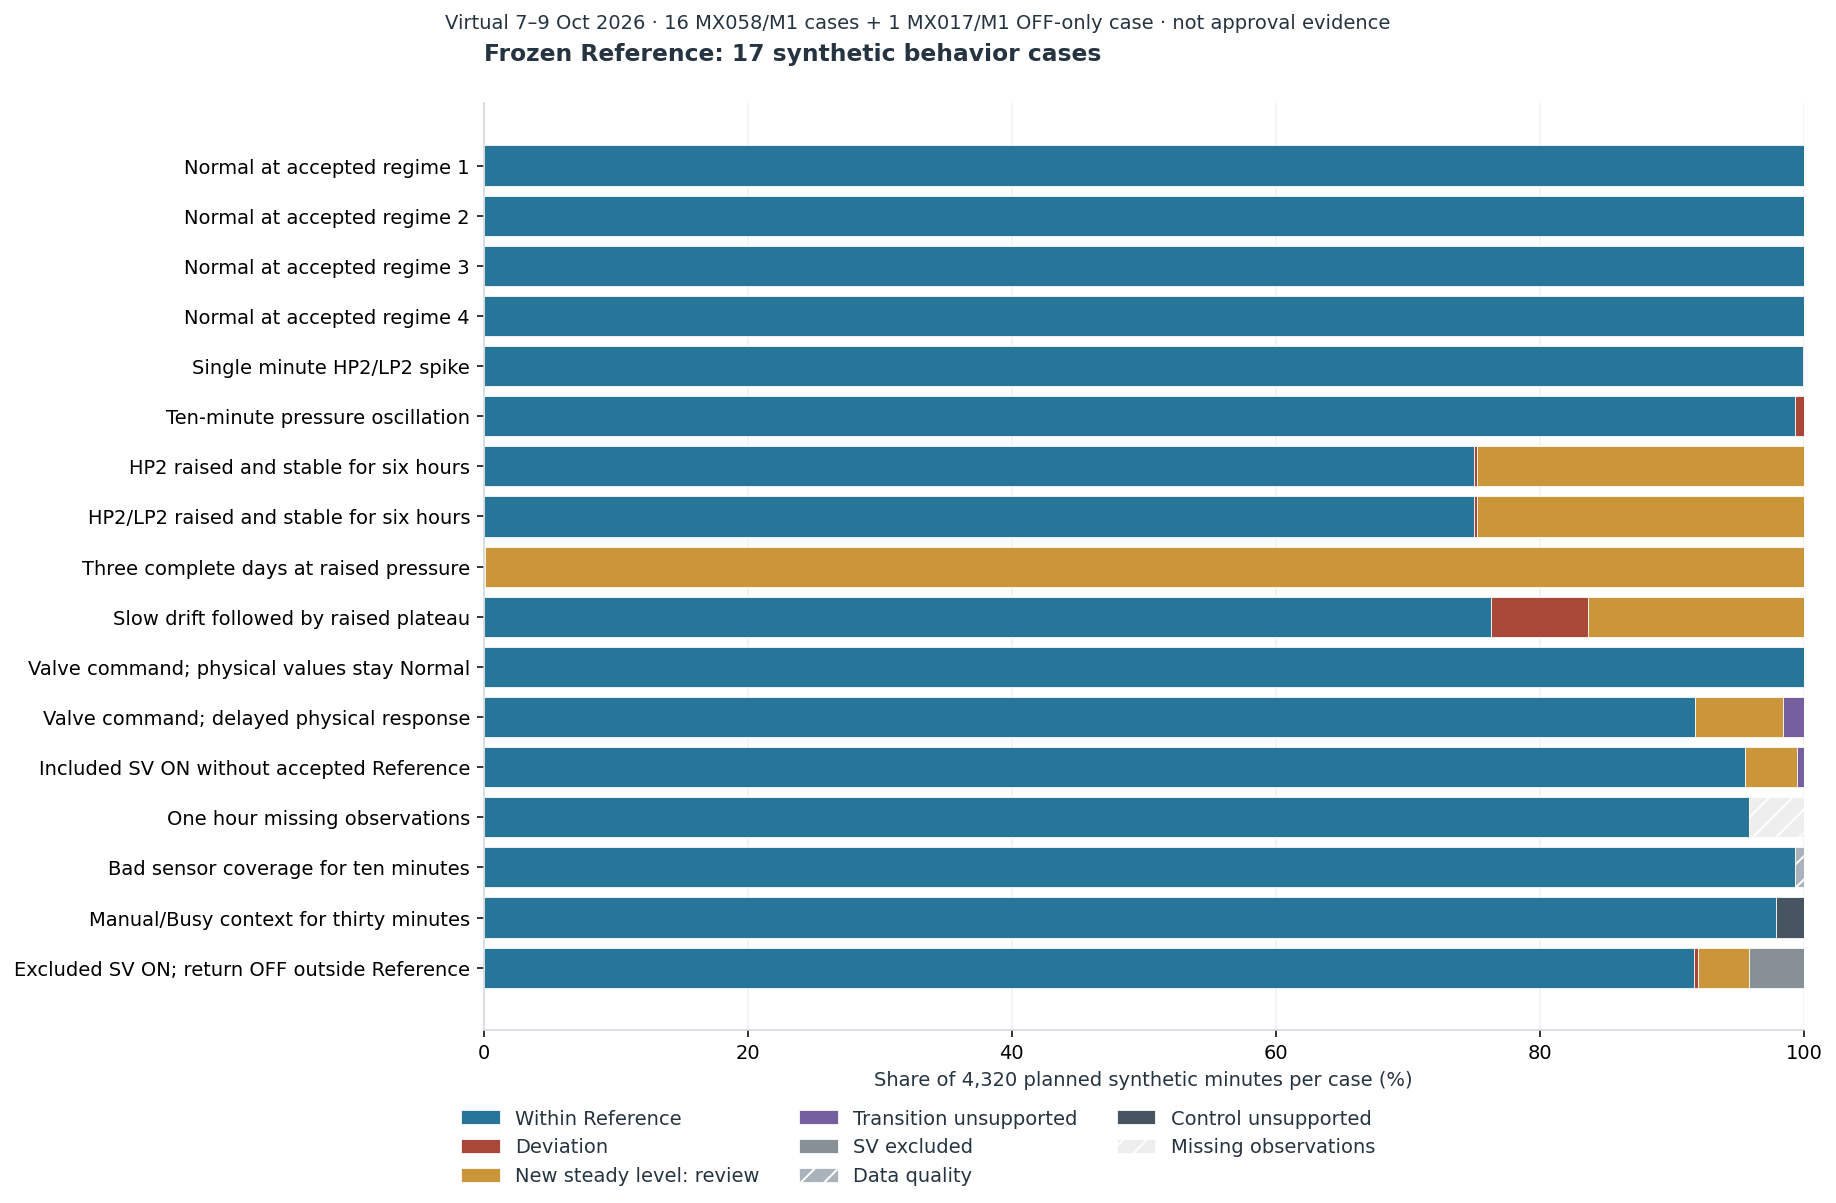

In [3]:
figure = composition()
display(Image(filename=str(OUT / 'scenario-composition.png')))
plt.close(figure)


### 2. Exact validation accounting

`Metrics only` checks the existing numerical conditions; it does not include source contracts, engineering review, included-state completeness or synthetic provenance. Every scenario is explicitly barred from approval.


In [4]:
table = pd.DataFrame([{'Case': c['case'], 'Supported min': c['receipt']['supported_minutes'],
    'Flag min': sum(c['categories'].get(k, 0) for k in ['STEADY_DEVIATION', 'UNEXPECTED_TRANSITION']),
    'Flag %': round(c['receipt']['flag_pct'], 3), 'Unresolved min': c['receipt']['unresolved_minutes'],
    'Missing min': c['missing_minutes'], 'Metrics only': c['metrics_only_within_gate'], 'Approval evidence': False}
    for c in result['cases']])
display(table)


,Case,Supported min,Flag min,Flag %,Unresolved min,Missing min,Metrics only,Approval evidence
0,normal_regime_1,4320,0,0.000,0,0,True,False
1,normal_regime_2,4320,0,0.000,0,0,True,False
2,normal_regime_3,4320,0,0.000,0,0,True,False
3,normal_regime_4,4320,0,0.000,0,0,True,False
4,spike_1m,4320,3,0.069,0,0,True,False
5,oscillation_10m,4320,30,0.694,0,0,True,False
6,hp2_plateau,3252,12,0.369,1068,0,False,False
7,cp2_plateau,3252,12,0.369,1068,0,False,False
8,all_day_plateau,4,4,100.000,4316,0,False,False
9,slow_drift,3612,315,8.721,708,0,False,False


### 3. Raised stable CP2 without a control transition

Pressure rises at07:00and stays high for six hours. Initial movement is a deviation; after the five-minute stability observation it becomes a new steady level requiring review. Nothing updates the frozen reference. Of1,080raisedminutes, allremain outside accepted Normal.


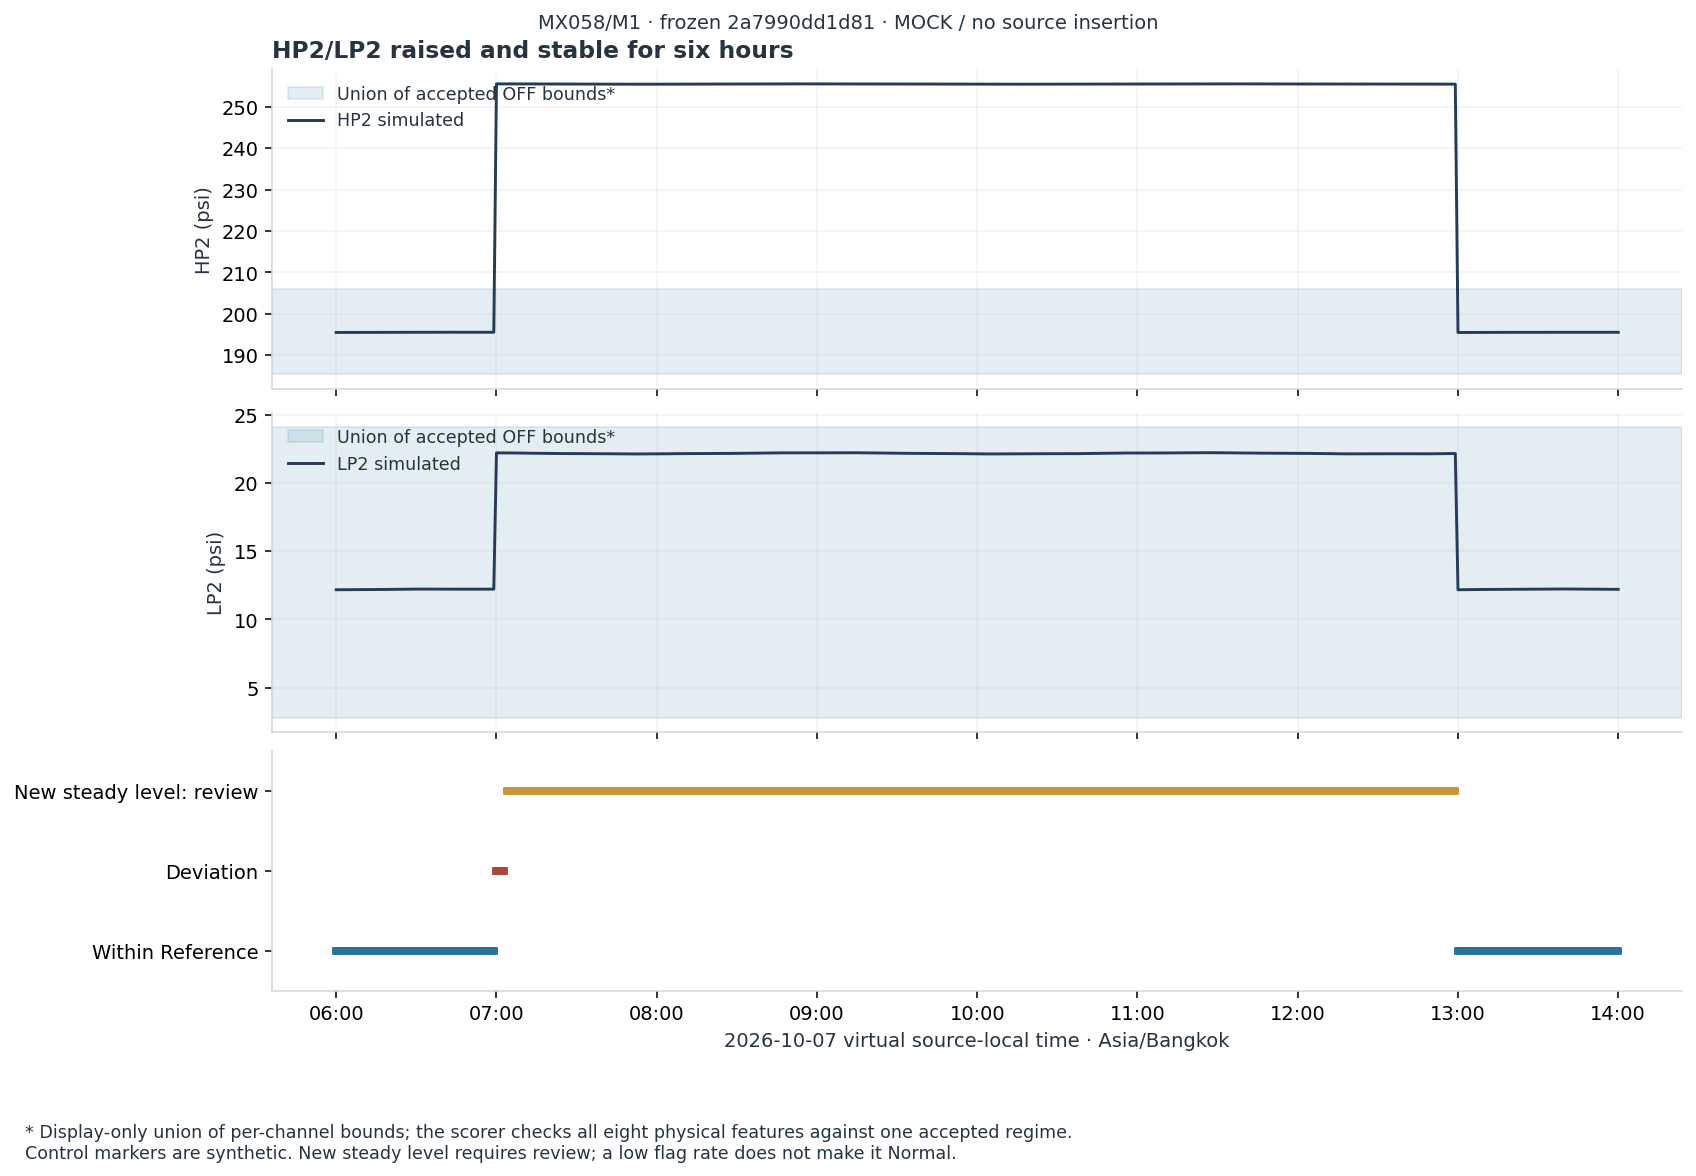

In [5]:
figure = timeline('cp2_plateau')
display(Image(filename=str(OUT / 'cp2_plateau-timeline.png')))
plt.close(figure)

### 4. Delayed pressure response after Valve command

Valve changes at06:59:30. Physical values remain within Reference until07:10, then rise. Normal initial values do not erase the control event. No accepted template exists in this actualProfile, so unsupported transition/new-level evidence blocks numerical acceptance. This is not proof the response is faulty or healthy.


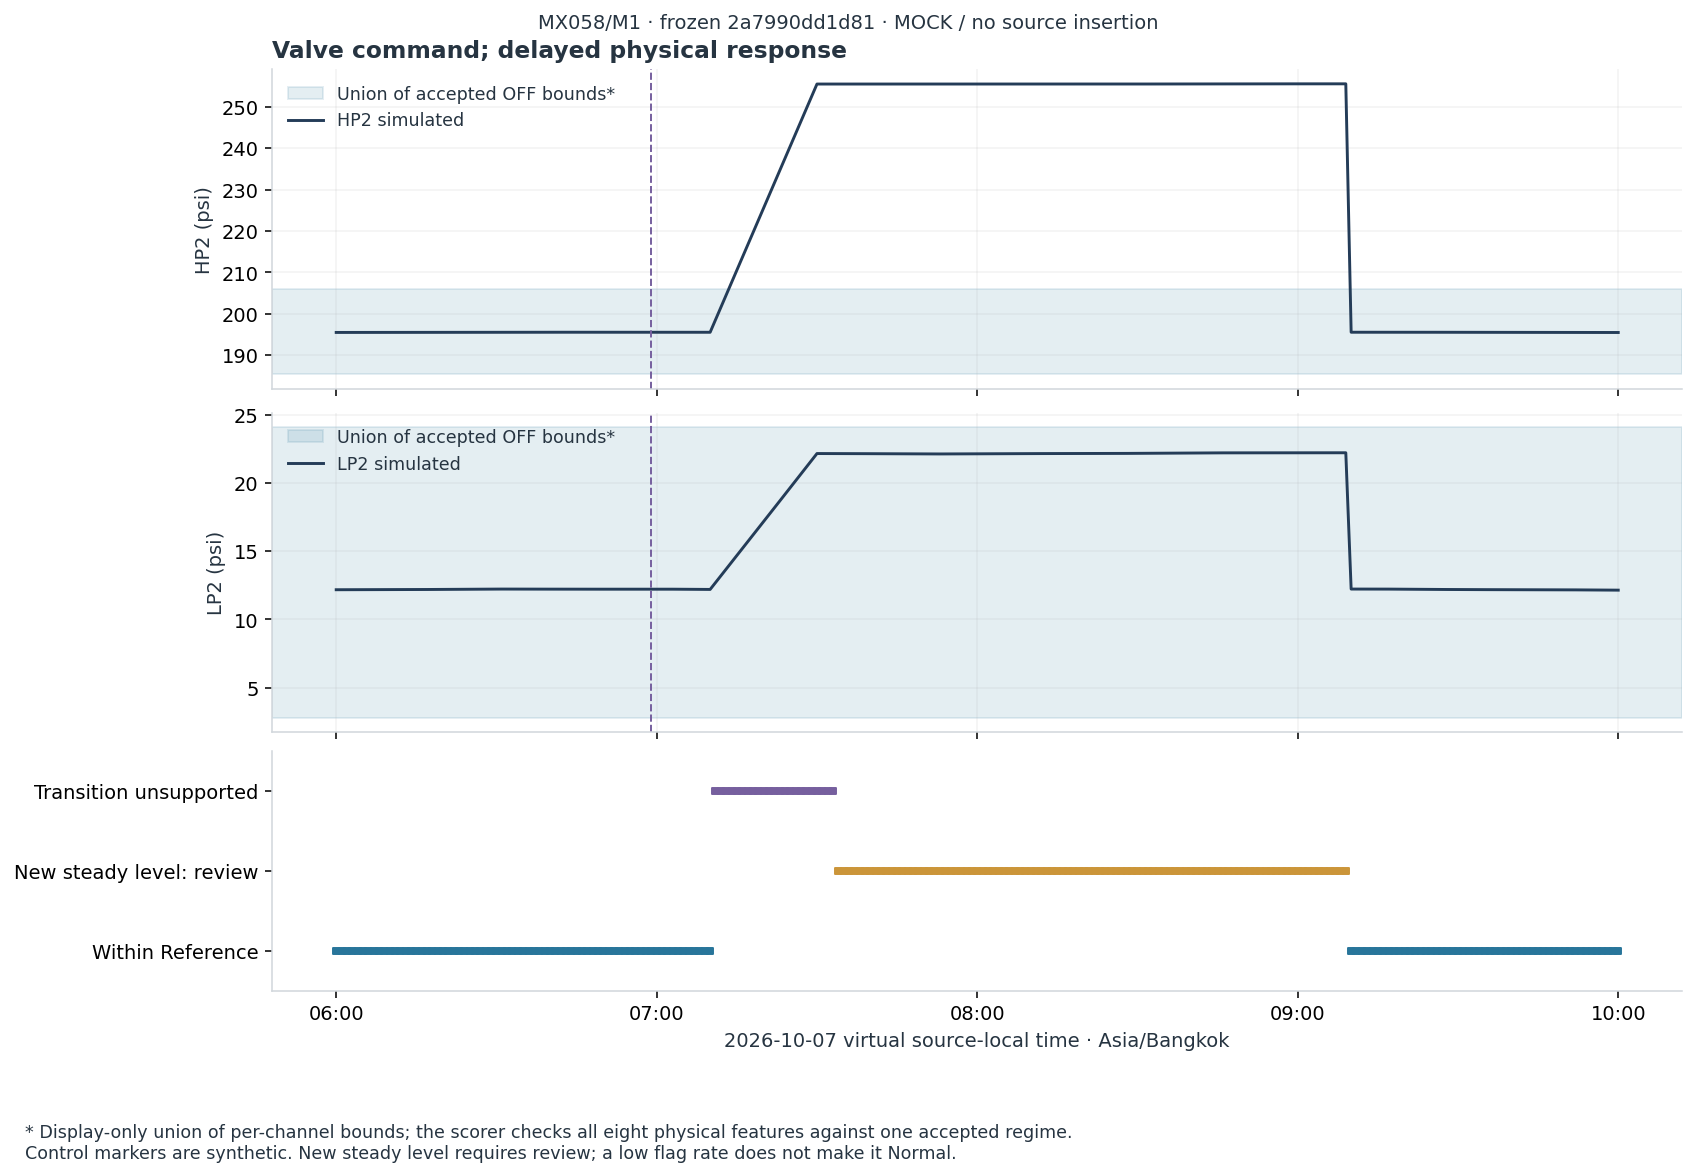

In [6]:
figure = timeline('valve_delayed_response', until=600)
display(Image(filename=str(OUT / 'valve_delayed_response-timeline.png')))
plt.close(figure)

### 5. Excluded SV ON and immediate return check

The actual saved MX017/M1 OFF-only review is used without editing its scope. ON07:00–08:00is excluded while raw feature evidence remains in this QA file. The first OFF minute at08:00is evaluated and flagged when still outsideReference; there is no cooldown.


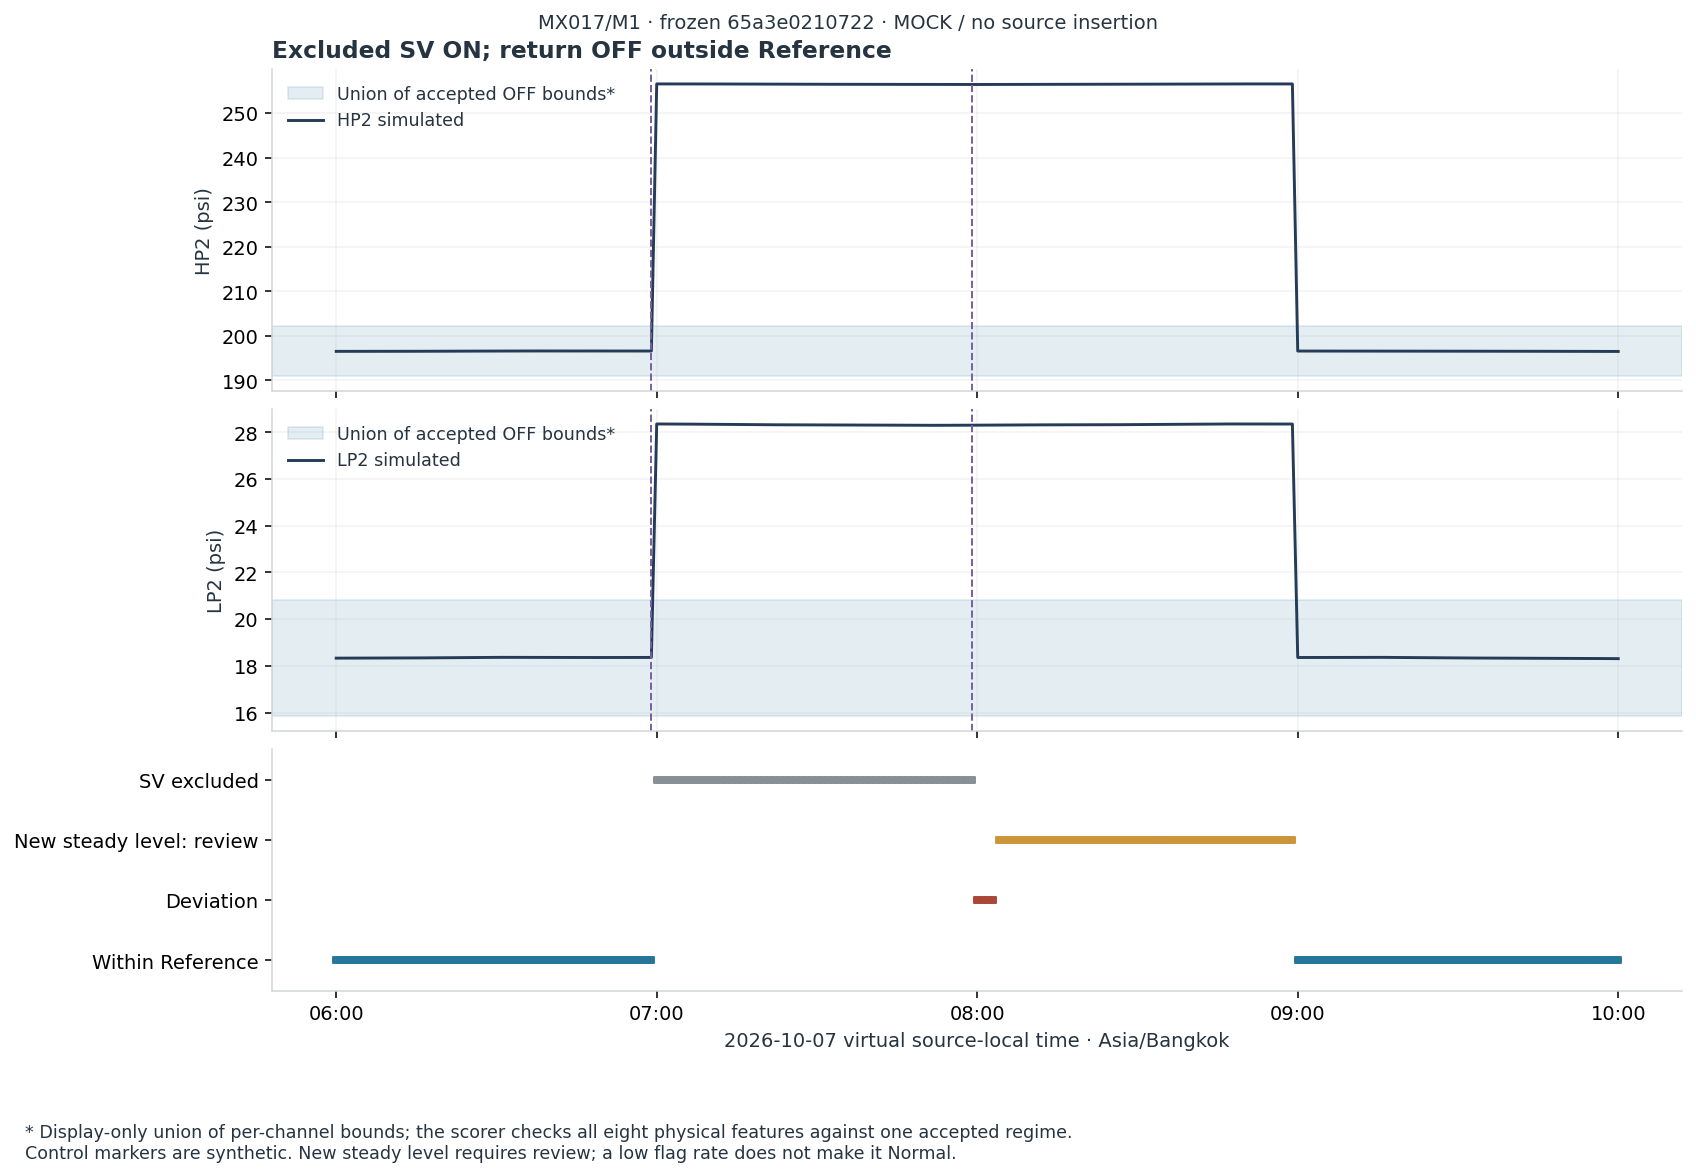

In [7]:
figure = timeline('excluded_on_return_outside', until=600)
display(Image(filename=str(OUT / 'excluded_on_return_outside-timeline.png')))
plt.close(figure)

## Takeaways

- Normal at all four accepted MX058 levels remains withinReference; command changes alone are not physical anomalies.
- A stable abnormal plateau does not disappear: `NEW_STEADY_LEVEL` creates unresolved review evidence even when aggregate `flag_pct` is small.
- A1-minute spike is detected, but3minutes across4,320minutes gives0.0695%, under the current1%aggregate threshold. This Profile acceptance statistic is not a statement that the spike is safe, nor an operational episode alert guarantee.
- Missing ON/Transition Reference requires coverage/review, not a blanket delay or automatically treating those observations asNormal. ExcludedON retains evidence and returningOFF is checked immediately.
- Missing/bad-quality/manual-control cases can have numerically lowflags because those minutes are not scored. Inspect daily quality/missing/unsupported counts; never read lowflags as certification.
- All17cases areMOCK/nonprospective and cannot createActive. Actual source afterfreeze, Raw/ingestion/manual realfuture acceptance and verified engineering/contracts remain untested by these synthetic scenarios.
